# Predicting English Grammar Proficiency and Native Language

## Introduction
**Problem statement.** We use a large online English grammar quiz to answer two questions about adult English learners:
1. **Task 1: Proficiency prediction.** Can a learner's language background (when they started English, time spent in English-speaking countries, native language, education, etc.) predict whether they reach near-native grammar proficiency?
2. **Task 2: Native-language prediction.** Can the pattern of grammar questions a learner answers right or wrong predict their native language?

**Dataset.** Hartshorne, Tenenbaum & Pinker (2018), *A critical period for second language acquisition: Evidence from 2/3 million English speakers*, `data.csv` and `compiled.csv` from [osf.io/pyb8s](https://osf.io/pyb8s).
About 670,000 participants took an online quiz with 132 grammar questions and answered questions about their language background. The authors scored each person on 95 of the questions, the ones native speakers reliably agree on.

## Setup
1. Download `data.csv` and `compiled.csv` from https://osf.io/pyb8s into this folder (only needed to rerun 01_cleaning.ipynb; both are too large for GitHub)
2. pip install -r requirements.txt
3. Run the notebooks in order: 01_cleaning.ipynb → task1.ipynb → task2.ipynb
   (task1 and task2 load the cleaned .parquet files already in the repo, so they run without step 1)

**Notebook outline**
- **Part 1:** data cleaning, exploration and feature engineering
- **Part 2:** Task 1, proficiency prediction
- **Part 3:** Task 2, native-language prediction

---

# Part 1: Data Cleaning, Exploration & Feature Engineering

**Outputs of this part**
- `clean_learners.parquet`: non-native learners with engineered background features and the `proficient` label (Task 1)
- `clean_native_lang_132.parquet`: learners with one of the 10 most common native languages, with their answers to all 132 questions (Task 2)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
log = {}   # running record of how many rows each step removes (for the writeup)

## 1. Load the data
Missing values in this file are stored as the text `NULL`, so we tell pandas to treat it as missing.

In [21]:
df = pd.read_csv("data.csv", na_values=["NULL"], low_memory=False)
log["start"] = len(df)
print(df.shape)
df.head()

(669498, 128)


,Unnamed: 0,id,date,time,gender,age,natlangs,primelangs,dyslexia,psychiatric,...,q34_6,q34_8,q35_1,q35_2,q35_4,q35_5,q35_7,q35_8,correct,elogit
0,1,2.0,2014-05-29,01:00:55,male,31,English,English,0,0,...,1,1,1,1,1,1,1,1,0.978947,3.621671
1,2,3.0,2014-05-29,01:01:03,male,30,English,English,0,1,...,1,1,1,1,1,1,1,1,1.000000,5.252273
2,3,3.0,2014-05-29,01:01:03,male,30,English,English,0,1,...,1,1,1,1,1,1,1,1,1.000000,5.252273
3,4,4.0,2014-05-29,01:01:13,male,19,English,English,0,0,...,1,1,1,1,1,0,1,1,0.905263,2.208853
4,5,5.0,2014-05-29,01:01:19,male,20,"Chinese/Mandarin, English","Chinese/Mandarin, English",0,0,...,1,1,1,1,1,0,1,1,0.947368,2.800602


## 2. Check the score column
The authors' `processing.R` script scored each person on 95 of the 132 grammar decisions: the ones native speakers reliably agreed on. Each `q` column is 1 (right) or 0 (wrong).
`correct` should equal the mean of those columns; we confirm that ourselves.

In [22]:
q_cols = [c for c in df.columns if c.startswith("q")]
print(len(q_cols), "scored questions")
print("max difference between our score and `correct`:", (df[q_cols].mean(axis=1) - df["correct"]).abs().max())

95 scored questions
max difference between our score and `correct`: 4.996003610813204e-16


## 3. Overview: missing values and columns with one value

In [23]:
meta = [c for c in df.columns if not c.startswith("q")]
overview = pd.DataFrame({
    "missing_share": df[meta].isna().mean().round(3),
    "n_unique": df[meta].nunique(),
}).sort_values("missing_share", ascending=False)
overview

,missing_share,n_unique
Ir_region,0.982,330
Can_region,0.926,214
UK_constituency,0.861,7300
UK_region,0.855,28
US_region,0.747,4584
Ebonics,0.747,3
Lived_Eng_per,0.449,1431
Eng_country_yrs,0.432,89
house_Eng,0.432,2
type,0.406,54


## 4. Remove duplicates and uninformative columns
- **Duplicate participant IDs:** keep the first attempt.
- **Constant columns** (same value for everyone): `dictionary`, `dyslexia`, `already_participated`.
- **Admin columns:** row index, date, time, `tests`.
- **Region columns:** 75–98% missing and only apply to specific countries.
- **`type`:** 33% missing among learners and duplicates the native-language information.

In [24]:
n0 = len(df)
df = df.drop_duplicates("id", keep="first")
log["duplicates_removed"] = n0 - len(df)

drop_cols = ["Unnamed: 0", "date", "time", "tests", "dictionary", "dyslexia", "already_participated",
             "Ir_region", "Can_region", "UK_region", "UK_constituency", "US_region", "Ebonics", "type"]
df = df.drop(columns=drop_cols)
print("duplicates removed:", log["duplicates_removed"])
print("shape now:", df.shape)

duplicates removed: 5
shape now: (669493, 114)


## 5. Sanity checks on ages
`processing.R` already removed impossible rows (starting age after current age, children reporting university degrees, ages outside 7–89). We verify that.

In [25]:
print("Eng_start > age:", (df.Eng_start > df.age).sum())
print("age range:", df.age.min(), "-", df.age.max())
print("Eng_country_yrs > age:", (df.Eng_country_yrs > df.age).sum())

Eng_start > age: 0
age range: 7 - 89
Eng_country_yrs > age: 0


## 6. Define the proficiency label
We use the score distribution of **monolingual native English speakers** (`Eng_little == "monoeng"`) as the benchmark.
A learner is **proficient** if they score at or above the **25th percentile** of native speakers.
The 10th percentile was too lenient: it would label about 61% of learners proficient, because native scores are bunched near the top.

10th percentile of native scores: 0.9263
25th percentile of native scores: 0.9579
50th percentile of native scores: 0.9789


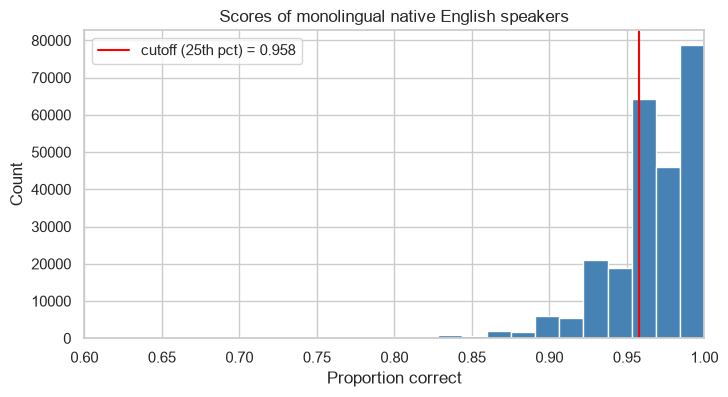

In [26]:
native = df.loc[df.Eng_little == "monoeng", "correct"]
for p in [0.10, 0.25, 0.50]:
    print(f"{int(p*100)}th percentile of native scores: {native.quantile(p):.4f}")
cutoff = native.quantile(0.25)

plt.figure(figsize=(8, 4))
plt.hist(native, bins=60, color="steelblue")
plt.axvline(cutoff, color="red", label=f"cutoff (25th pct) = {cutoff:.3f}")
plt.xlim(0.6, 1.0)
plt.xlabel("Proportion correct"); plt.ylabel("Count")
plt.title("Scores of monolingual native English speakers")
plt.legend(); plt.show()

## 7. Build the learner dataset
Learners are people who don't list English as a native language (`nat_Eng == 0`).
We also drop people with `nat_Eng == 0` but `speaker_cat == "native"`: they started English at birth without listing it as native, so it's ambiguous which group they belong to.

In [27]:
n_nonnative = (df.nat_Eng == 0).sum()
learners = df[(df.nat_Eng == 0) & (df.speaker_cat != "native")].copy()
log["ambiguous_native_removed"] = n_nonnative - len(learners)
learners["proficient"] = (learners.correct >= cutoff).astype(int)

print("learners:", len(learners), "| ambiguous rows removed:", log["ambiguous_native_removed"])
print("proficient share:", round(learners.proficient.mean(), 3))

learners: 355805 | ambiguous rows removed: 22060
proficient share: 0.365


## 8. Clean education into an ordered scale
Over 99.9% of learners chose one of the 7 English options. About 350 entries are machine-translated or garbled-character versions in other languages.
Since they're so few, we drop them rather than guess at translations.

In [28]:
edu_map = {
    "Didn't Finish High School (less than 13 years ed)": 1,
    "Haven't Finished High School (less than 13 years ed)": 1,
    "High School Degree (12-13 years)": 2,
    "Some Undergrad (higher ed)": 3,
    "Undergraduate Degree (3-5 years higher ed)": 4,
    "Some Graduate School": 5,
    "Graduate Degree": 6,
}
learners["education_level"] = learners.education.map(edu_map)
log["education_unmapped_removed"] = learners.education_level.isna().sum()
learners = learners.dropna(subset=["education_level"])
learners["education_level"] = learners.education_level.astype(int)
print("rows removed (non-English education entries):", log["education_unmapped_removed"])
learners.education_level.value_counts().sort_index()

rows removed (non-English education entries): 307


education_level
1     13276
2     48083
3     34360
4     78304
5     30946
6    150529
Name: count, dtype: int64

## 9. Missing values
Among learners, only a few background columns have missing values:
- `Eng_country_yrs` and `house_Eng` are missing for the same ~3% of people. We fill both with the median (0) and add a `background_missing` flag, so the model can tell if missingness itself means something.
- `natlangs` (2%): native language unknown. We keep these rows for Task 1, labeled `"Unknown"`.

In [29]:
print(learners[["Eng_country_yrs", "house_Eng", "natlangs", "primelangs", "currcountry"]].isna().mean().round(3))

learners["background_missing"] = (learners.Eng_country_yrs.isna() | learners.house_Eng.isna()).astype(int)
for c in ["Eng_country_yrs", "house_Eng"]:
    learners[c] = learners[c].fillna(learners[c].median())
learners["natlangs"] = learners.natlangs.fillna("Unknown")
learners["primelangs"] = learners.primelangs.fillna("Unknown")

Eng_country_yrs    0.033
house_Eng          0.033
natlangs           0.021
primelangs         0.021
currcountry        0.046
dtype: float64


## 10. Feature engineering
| Feature | Meaning |
|---|---|
| `years_exposure` | age − age started English |
| `start_age_group` | starting-age groups: 0–3, 4–7, 8–12, 13–17, 18+ (critical-period idea) |
| `lived_eng_share` | fraction of their English-learning years spent in an English-speaking country |
| `n_native_langs`, `n_prime_langs` | number of native / current primary languages listed |
| `prime_Eng` | English is one of their current primary languages (rebuilt: the original flag was 0 for every learner) |
| `lives_eng_country` | currently lives in a mainly English-speaking country |
| `native_lang_grp` | first-listed native language; the 15 most common kept, others grouped as "Other" (missing kept as "Unknown") |
| `lang_family` | language family of the first-listed native language |

In [30]:
learners["years_exposure"] = learners.age - learners.Eng_start
learners["start_age_group"] = pd.cut(learners.Eng_start, bins=[-1, 3, 7, 12, 17, 200],
                                     labels=["0-3", "4-7", "8-12", "13-17", "18+"]).astype(str)
learners["lived_eng_share"] = np.where(learners.years_exposure > 0,
                                       learners.Eng_country_yrs / learners.years_exposure, 0).clip(0, 1)

learners["n_native_langs"] = learners.natlangs.str.count(",") + 1
learners["n_prime_langs"] = learners.primelangs.str.count(",") + 1

# The original prime_Eng flag is 0 for every learner, even though many list English as a primary language,
# so we rebuild it from primelangs.
learners["prime_Eng"] = learners.primelangs.str.contains("English").astype(int)

eng_countries = ["United States", "United Kingdom", "Canada", "Australia", "New Zealand",
                 "Ireland (Republic of)", "Singapore", "South Africa"]
learners["lives_eng_country"] = learners.currcountry.isin(eng_countries).astype(int)

learners["first_native_lang"] = learners.natlangs.str.split(",").str[0].str.strip()
top15 = learners.first_native_lang[learners.first_native_lang != "Unknown"].value_counts().head(15).index
learners["native_lang_grp"] = learners.first_native_lang.where(learners.first_native_lang.isin(top15) | (learners.first_native_lang == "Unknown"), "Other")

family = {
    "Finnish": "Uralic", "Hungarian": "Uralic", "Estonian": "Uralic",
    "Turkish": "Turkic",
    "German": "Germanic", "Dutch": "Germanic", "Swedish": "Germanic", "Norwegian": "Germanic",
    "Danish": "Germanic", "Icelandic": "Germanic",
    "Spanish": "Romance", "French": "Romance", "Portuguese": "Romance", "Italian": "Romance",
    "Romanian": "Romance", "Catalan": "Romance",
    "Russian": "Slavic", "Polish": "Slavic", "Czech": "Slavic", "Ukrainian": "Slavic", "Slovak": "Slavic",
    "Serbian": "Slavic", "Croatian": "Slavic", "Bulgarian": "Slavic", "Slovenian": "Slavic",
    "Chinese/Mandarin": "Sino-Tibetan", "Chinese/Cantonese/Yue": "Sino-Tibetan",
    "Chinese/Taiwanese/Min Nan/Hokkien": "Sino-Tibetan",
    "Greek": "Hellenic", "Indonesian": "Austronesian", "Tagalog": "Austronesian", "Malay": "Austronesian",
    "Japanese": "Japonic", "Korean": "Koreanic", "Arabic": "Afro-Asiatic", "Hebrew": "Afro-Asiatic",
    "Hindi": "Indo-Iranian", "Persian/Farsi": "Indo-Iranian", "Lithuanian": "Baltic", "Latvian": "Baltic",
}
learners["lang_family"] = learners.first_native_lang.map(family).fillna("Other")

learners[["years_exposure", "start_age_group", "lived_eng_share", "n_native_langs",
          "lives_eng_country", "native_lang_grp", "lang_family"]].head()

,years_exposure,start_age_group,lived_eng_share,n_native_langs,lives_eng_country,native_lang_grp,lang_family
9,17,8-12,1.000000,2,1,Chinese/Mandarin,Sino-Tibetan
13,14,4-7,0.000000,1,0,Other,Other
14,19,18+,0.000000,1,0,Spanish,Romance
16,17,8-12,0.058824,1,0,Dutch,Germanic
17,25,4-7,1.000000,1,1,Other,Other


## 11. Exploration
### Class balance

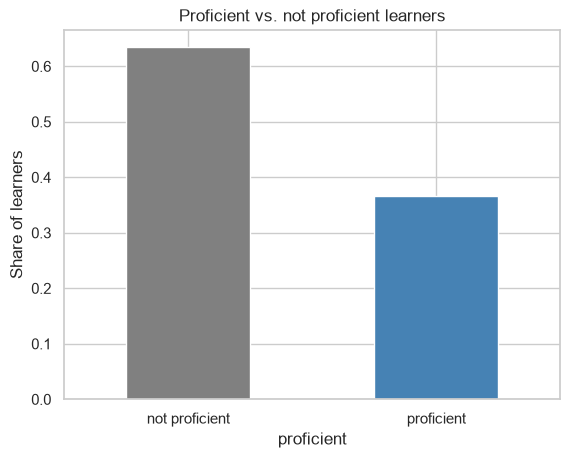

In [31]:
learners.proficient.value_counts(normalize=True).rename({0: "not proficient", 1: "proficient"}).plot.bar(color=["gray", "steelblue"])
plt.ylabel("Share of learners"); plt.title("Proficient vs. not proficient learners"); plt.xticks(rotation=0); plt.show()

### Proficiency by age started learning English

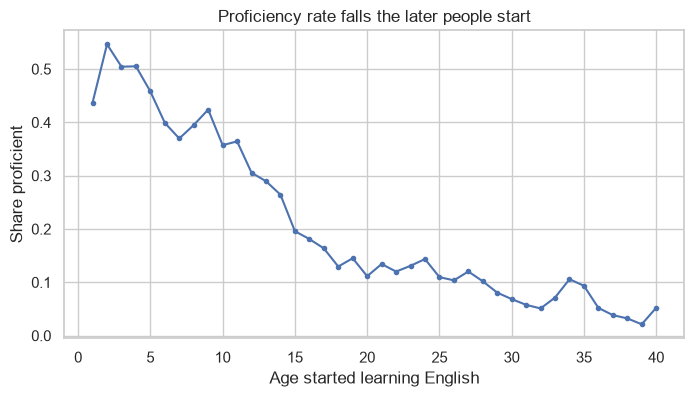

In [32]:
rate = learners[learners.Eng_start <= 40].groupby("Eng_start").proficient.mean()
plt.figure(figsize=(8, 4))
rate.plot(marker="o", ms=3)
plt.xlabel("Age started learning English"); plt.ylabel("Share proficient")
plt.title("Proficiency rate falls the later people start"); plt.show()

### Proficiency by time spent living in an English-speaking country

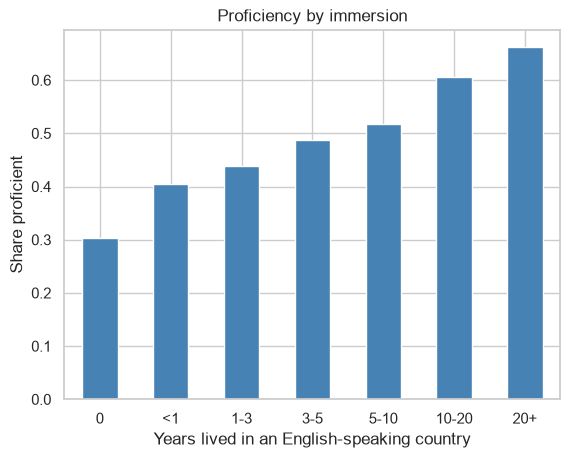

In [33]:
bins = pd.cut(learners.Eng_country_yrs, bins=[-1, 0, 1, 3, 5, 10, 20, 100],
              labels=["0", "<1", "1-3", "3-5", "5-10", "10-20", "20+"])
learners.groupby(bins, observed=True).proficient.mean().plot.bar(color="steelblue")
plt.xlabel("Years lived in an English-speaking country"); plt.ylabel("Share proficient")
plt.title("Proficiency by immersion"); plt.xticks(rotation=0); plt.show()

### Scores by native language (15 most common)

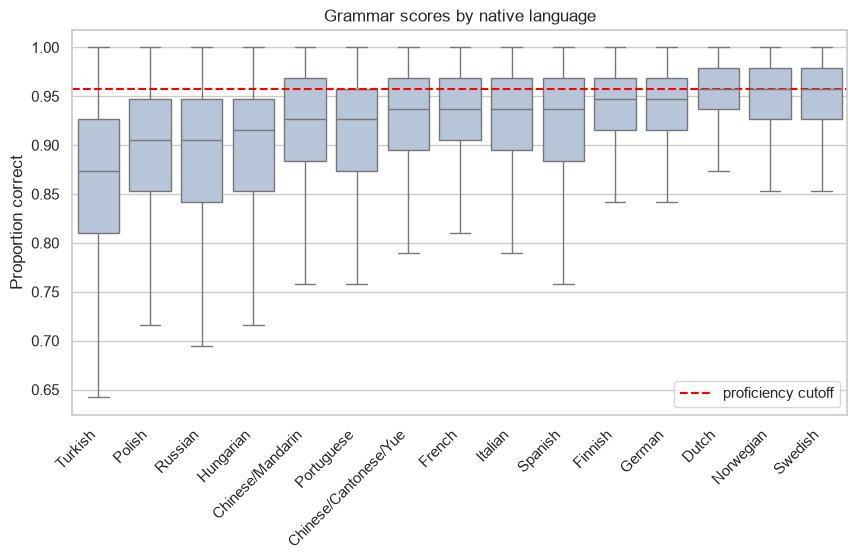

In [34]:
order = learners[~learners.native_lang_grp.isin(["Other", "Unknown"])].groupby("native_lang_grp").correct.median().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=learners[learners.native_lang_grp.isin(order)], x="native_lang_grp", y="correct",
            order=order, showfliers=False, color="lightsteelblue")
plt.axhline(cutoff, color="red", ls="--", label="proficiency cutoff")
plt.xticks(rotation=45, ha="right"); plt.xlabel(""); plt.ylabel("Proportion correct")
plt.title("Grammar scores by native language"); plt.legend(); plt.show()

### Hardest questions for learners compared with native speakers

In [35]:
gap = pd.DataFrame({
    "learners": learners[q_cols].mean(),
    "natives": df.loc[df.Eng_little == "monoeng", q_cols].mean(),
})
gap["gap"] = gap.natives - gap.learners
gap.sort_values("gap", ascending=False).head(15).round(3)

,learners,natives,gap
q34_1,0.717,0.957,0.240
q11_4,0.679,0.908,0.229
q18_3,0.775,0.947,0.172
q34_4,0.686,0.850,0.164
q24_4,0.839,0.989,0.150
q22_2,0.797,0.939,0.143
q34_6,0.801,0.942,0.141
q19_1,0.832,0.972,0.140
q13_3,0.768,0.907,0.139
q24_3,0.852,0.989,0.138


### How the numeric features relate to each other and to the label

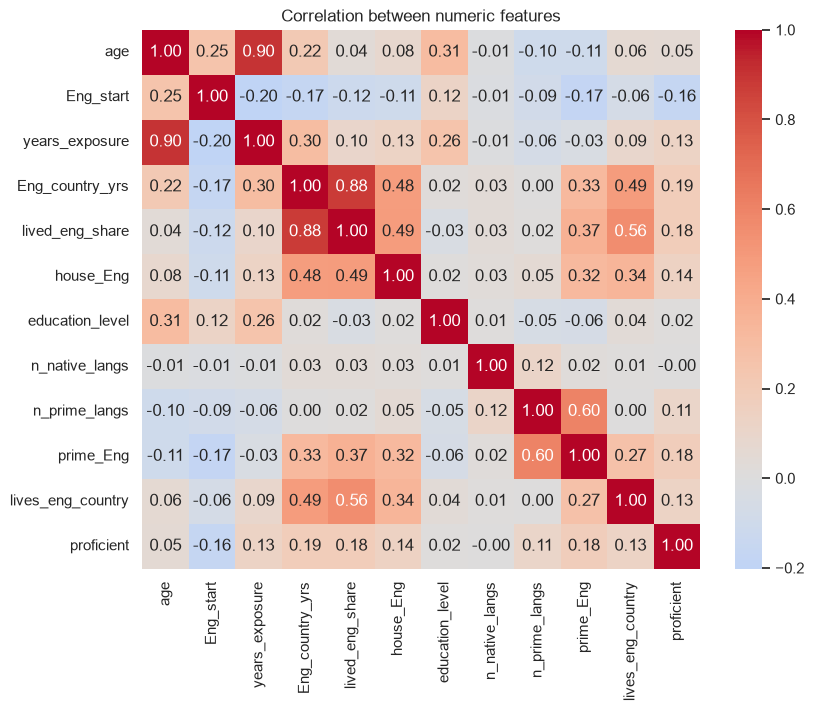

In [36]:
num = ["age", "Eng_start", "years_exposure", "Eng_country_yrs", "lived_eng_share", "house_Eng",
       "education_level", "n_native_langs", "n_prime_langs", "prime_Eng", "lives_eng_country", "proficient"]
plt.figure(figsize=(9, 7))
sns.heatmap(learners[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features"); plt.show()

## 12. Save Task 1 data (proficiency prediction)
**Model inputs:** background features only.
**Do not use as inputs:** `score` (the quiz score that defines the label), `elogit`, `Eng_little`, `speaker_cat`.

In [37]:
task1_cols = ["id", "age", "gender", "Eng_start", "years_exposure", "start_age_group", "Eng_country_yrs",
              "lived_eng_share", "house_Eng", "background_missing", "education_level", "psychiatric",
              "prime_Eng", "lives_eng_country", "n_native_langs", "n_prime_langs", "native_lang_grp",
              "lang_family", "proficient", "correct"]
task1 = learners[task1_cols].rename(columns={"correct": "score"})
task1.to_parquet("clean_learners.parquet", engine="pyarrow", compression="snappy", index=False)
print(task1.shape)
task1.head()

(355498, 20)


,id,age,gender,Eng_start,years_exposure,start_age_group,Eng_country_yrs,lived_eng_share,house_Eng,background_missing,education_level,psychiatric,prime_Eng,lives_eng_country,n_native_langs,n_prime_langs,native_lang_grp,lang_family,proficient,score
9,11.0,25,female,8,17,8-12,17.0,1.000000,0.0,0,5,0,1,1,2,1,Chinese/Mandarin,Sino-Tibetan,1,0.978947
13,15.0,20,female,6,14,4-7,0.0,0.000000,1.0,0,4,0,0,0,1,1,Other,Other,1,0.957895
14,16.0,37,male,18,19,18+,0.0,0.000000,0.0,0,6,0,0,0,1,2,Spanish,Romance,0,0.831579
16,19.0,29,female,12,17,8-12,1.0,0.058824,0.0,0,6,0,1,0,1,2,Dutch,Germanic,1,0.978947
17,1764.0,29,female,4,25,4-7,29.0,1.000000,1.0,0,6,0,1,1,1,1,Other,Other,1,0.968421


## 13. Save Task 2 data (native-language prediction)
Learners who list exactly **one** native language, restricted to the 10 most common.

**Inputs:** the 95 right/wrong columns, **plus the 37 grammar questions the original authors left out of the score** because native speakers from different English-speaking countries disagree on them (mostly American vs. British usage).
They're useless for a proficiency score, but potentially useful for Task 2: which variety of English someone learned may relate to their native language.
These come from the raw responses in `compiled.csv` (same source, osf.io/pyb8s), merged by participant `id`, and are prefixed `d_` (for "dialect"). They record which answer the person picked, not right/wrong.

In [38]:
single = learners[~learners.natlangs.str.contains(",") & (learners.natlangs != "Unknown")]
top10 = single.natlangs.value_counts().head(10).index.tolist()
task2 = single[single.natlangs.isin(top10)][["id"] + q_cols + ["natlangs"]].rename(columns={"natlangs": "native_lang"})

# Add the 37 unscored questions from the raw responses file
raw = pd.read_csv("compiled.csv", na_values=["NULL"], low_memory=False,
                  usecols=lambda c: c == "id" or c.startswith("q")).drop_duplicates("id")
extra_items = [c for c in raw.columns if c.startswith("q") and c not in q_cols]
raw = raw[["id"] + extra_items].rename(columns={c: "d_" + c for c in extra_items})
task2 = task2.merge(raw, on="id", how="left")
print("unscored questions added:", len(extra_items), "| rows missing them:", task2["d_" + extra_items[0]].isna().sum())

task2.to_parquet("clean_native_lang_132.parquet", index=False)
print("top 10 languages:", top10)
print(task2.shape)
task2.native_lang.value_counts()

unscored questions added: 37 | rows missing them: 0
top 10 languages: ['Finnish', 'Turkish', 'German', 'Russian', 'Hungarian', 'Polish', 'Dutch', 'Swedish', 'Spanish', 'Portuguese']
(223288, 134)


native_lang
Finnish       39787
Turkish       36070
German        24405
Russian       22680
Hungarian     22010
Polish        18541
Dutch         17793
Swedish       16271
Spanish       15555
Portuguese    10176
Name: count, dtype: int64

## 14. Cleaning log (row counts for the writeup)

In [39]:
log["final_task1_rows"] = len(task1)
log["final_task2_rows"] = len(task2)
log["prime_Eng_learners"] = int(task1.prime_Eng.sum())
log["cutoff"] = round(cutoff, 4)
log["proficient_share"] = round(task1.proficient.mean(), 3)
pd.Series(log)

start                         669498.0000
duplicates_removed                 5.0000
ambiguous_native_removed       22060.0000
education_unmapped_removed       307.0000
final_task1_rows              355498.0000
final_task2_rows              223288.0000
prime_Eng_learners            124821.0000
cutoff                             0.9579
proficient_share                   0.3660
dtype: float64

In [40]:
# Table 1: rows removed at each cleaning step
steps = pd.DataFrame({
    "Step": ["Raw data", "Duplicate participant IDs", "Keep non-native speakers only",
             "Ambiguous native status", "Non-English education entries",
             "Task 2: one native language, 10 most common"],
    "Rows left": [log["start"], log["start"] - log["duplicates_removed"],
                  n_nonnative, n_nonnative - log["ambiguous_native_removed"],
                  log["final_task1_rows"], log["final_task2_rows"]],
})
steps["Rows removed"] = (-steps["Rows left"].diff()).fillna(0).astype(int)
steps.loc[5, "Rows removed"] = log["final_task1_rows"] - log["final_task2_rows"]
steps[["Step", "Rows removed", "Rows left"]]

,Step,Rows removed,Rows left
0,Raw data,0,669498
1,Duplicate participant IDs,5,669493
2,Keep non-native speakers only,291628,377865
3,Ambiguous native status,22060,355805
4,Non-English education entries,307,355498
5,"Task 2: one native language, 10 most common",132210,223288


In [41]:
# Table 2: share of learners labeled proficient under each cutoff
pd.DataFrame([{"Cutoff (native percentile)": f"{int(p*100)}th",
               "Score threshold": round(native.quantile(p), 3),
               "Learners labeled proficient": f"{(task1.score >= native.quantile(p)).mean():.1%}"}
              for p in [0.10, 0.25, 0.50]])

,Cutoff (native percentile),Score threshold,Learners labeled proficient
0,10th,0.926,59.2%
1,25th,0.958,36.6%
2,50th,0.979,17.7%
